# Communicate with a vLLM-served Qwen2.5-VL model for V-STaR

Sanity-check script: pick a V-STaR sample, overlay bbox/mask annotations on the video, save it to disk, then send it to the local vLLM server and print the model's answer.

## 1. Load the V-STaR test set

In [1]:
import json
import datasets

dataset = datasets.load_dataset("json", data_files="/projects/torresani-lab/ajay/datasets/V-STaR/V_STaR_test_with_qid.json", split="train")
print(len(dataset))

zeroshot_results = json.load(open("/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_zeroshot/2026-05-18_18-35-15/results.json"))
print(len(zeroshot_results))

2094
2094


## 2. Pick a sample and decode its video

Loads imports, selects `dataset[idx]`, and decodes the video frames at the same `min_pixels`/`max_pixels` budget used during training.

In [2]:
import os
import sys
import importlib

import numpy as np
import torch
from qwen_vl_utils import fetch_video

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")
import src.utils.annotation_utils
importlib.reload(src.utils.annotation_utils)
from src.utils.annotation_utils import load_mask_annotations, annotate_frames

# Pick a sample and decode its video at fixed token budget.
idx = 0
sample = dataset[idx]
zeroshot_answer = zeroshot_results[idx]['generated_answer']
print(sample['vid'], sample['qid'])

video_path = os.path.join("/projects/torresani-lab/ajay/datasets/V-STaR/videos", sample['vid'] + ".mp4")
video_input = fetch_video({
    "video": video_path,
    "min_pixels": 128 * 28 * 28,
    "max_pixels": 128 * 28 * 28,
    "fps": 1,
})
print("video_input:", video_input.shape)

7771650716 7771650716_0


qwen-vl-utils using torchcodec to read video.


video_input: torch.Size([60, 3, 224, 420])


## 3. Overlay annotations on the decoded frames

Loads the saved per-frame mask JSON for this `qid` and draws the chosen annotation type (`bbox` here) on top of the decoded frames.

In [26]:
annotation_root = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/uniform_sample_cap_768/2026-05-19_19-14-38"
annotation_type = "bbox" # "bbox" | "mask" | "outline"

# Options
annotate_bbox = False       # overlay bbox/mask/outline annotations
annotate_frame_nums = True  # overlay frame numbers (bottom-right, red)

annotated_input = video_input.clone()

if annotate_bbox:
    annotation_path = os.path.join(annotation_root, "masks", f"{sample['qid']}.json")
    record = load_mask_annotations(annotation_path)
    annotated_input = annotate_frames(annotated_input, record["masks_np"], annotation_type=annotation_type)
    annotated_input = torch.tensor(np.array(annotated_input)).permute(0, 3, 1, 2).to(torch.float32)

# Uniformly sample 16 frames
indices = np.linspace(0, annotated_input.shape[0] - 1, 16, dtype=int)
annotated_input = annotated_input[indices]

if annotate_frame_nums:
    import cv2

    def annotate_frame_numbers(frames: torch.Tensor, scale: float = 2.0, thickness: int = 3) -> torch.Tensor:
        annotated = []
        for i, frame in enumerate(frames):
            arr = cv2.cvtColor(frame.permute(1, 2, 0).numpy().astype(np.uint8), cv2.COLOR_RGB2BGR)
            h, w = arr.shape[:2]
            text = str(i)
            font = cv2.FONT_HERSHEY_SIMPLEX
            (tw, th), baseline = cv2.getTextSize(text, font, scale, thickness)
            x, y = w - tw - 8, h - baseline - 4
            cv2.putText(arr, text, (x, y), font, scale, (0, 0, 255), thickness, cv2.LINE_AA)
            annotated.append(torch.from_numpy(cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1))
        return torch.stack(annotated)

    annotated_input = annotate_frame_numbers(annotated_input)

print("annotated_input:", annotated_input.shape)

annotated_input: torch.Size([16, 3, 224, 420])


## 4. Write the annotated video to disk

vLLM's chat endpoint reads videos by `file://` URL, so we materialize the annotated frames as an mp4 in `dump/`.

In [27]:
from torchcodec.encoders import VideoEncoder

output_video_path = f"/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serve/dump/ann_{sample['qid']}.mp4"
VideoEncoder(annotated_input.to(torch.uint8), frame_rate=4).to_file(output_video_path)
print("wrote:", output_video_path)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serve/dump/ann_7771650716_0.mp4


## 5. Preview the first annotated frame

Quick visual check that the annotation overlay landed correctly before sending the video to the model.

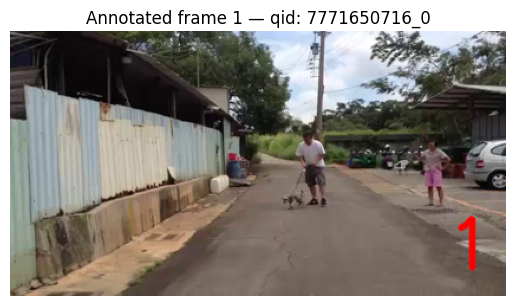

In [28]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input.shape[0])
any_frame = annotated_input[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — qid: {sample['qid']}")
plt.axis('off')
plt.show()

## 6. Build the chat request

Reads the system prompt, points the OpenAI client at the local vLLM server, and assembles the `(system, user-question + video)` message. Switch `model` between `"sft"` (LoRA adapter) and the base model id depending on how vLLM was launched.

In [29]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"

# Use "sft" when serving with LoRA (matches LORA_NAME in vllm_serve.sh).
# Use the base model name ("Qwen/Qwen2.5-VL-7B-Instruct") when serving without LoRA.
# model = "Qwen/Qwen2.5-VL-7B-Instruct"
model = "sft"

SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/train/openo3_red_bbox_frame_num_v2.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    SYSTEM_PROMPT = f.read()

# SYSTEM_PROMPT = "Explain what is happening inside the annotated red bounding box. Focus on the content within the box and provide a detailed description based on the visual information. Ignore any other elements outside the box and concentrate solely on describing the actions, objects, and interactions occurring within the red bounding box in the video frames."

n_frames = annotated_input.shape[0]
frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            {
                "type": "text",
                "text": frame_prompt + sample['question']
            },
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MIN_PIXELS": 128 * 28 * 28,
                "VIDEO_MAX_PIXELS": 128 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

## 7. Send the request and print the response

In [30]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message,
    max_tokens=768,
    seed=42,
    temperature=0,
)
response_text = chat_response.choices[0].message.content
print(response_text)

<think>The video shows a man in a white shirt walking on a paved street. As he walks, a small dog on a leash is positioned in front of him, moving forward as well. The dog is clearly visible in the foreground, with its body and head facing towards the camera, while the man's back is turned to the viewer. This is evident from the <obj>man in white shirt</obj> at <frame>1</frame> and the <obj>dog</obj> at <frame>1</frame>, which are both highlighted by red bounding boxes.</think>
<answer>A small dog on a leash is walking in front of the man in a white shirt.</answer>


In [16]:
print(f"Question: {sample['question']}")
print("Ground truth answer:", sample['answer'])
print("Zeroshot answer:", zeroshot_answer)

Question: what walks in front of a man in white?
Ground truth answer: a dog with a rope walks in front of a man in white.
Zeroshot answer: A dog walks in front of the man in white.
